In [1]:
import sys
import os
import numpy as np
import sympy as sp

# Add the parent directory and src directory to Python path
project_root = os.path.dirname(os.getcwd())
src_path = os.path.join(project_root, 'src')
sys.path.insert(0, project_root)
sys.path.insert(0, src_path)

# First import matrix_utils to make it available for seesaw module
#import matrix_utils

# Now we need to temporarily fix the import issue by importing functions into global namespace
from matrix_utils import (diagonalize_mass_matrix, mass_squared_differences,
                          create_symbolic_matrix, seesaw_approximation_symbolic,
                          substitute_numerical_values, symbolic_rotation_matrix,
                          sin_cos_from_tan_fraction)

# Add these to matrix_utils module namespace to satisfy relative imports
sys.modules['matrix_utils'].diagonalize_mass_matrix = diagonalize_mass_matrix
sys.modules['matrix_utils'].mass_squared_differences = mass_squared_differences
sys.modules['matrix_utils'].create_symbolic_matrix = create_symbolic_matrix
sys.modules['matrix_utils'].seesaw_approximation_symbolic = seesaw_approximation_symbolic
sys.modules['matrix_utils'].substitute_numerical_values = substitute_numerical_values
sys.modules['matrix_utils'].symbolic_rotation_matrix = symbolic_rotation_matrix
sys.modules['matrix_utils'].sin_cos_from_tan_fraction = sin_cos_from_tan_fraction

# Now import seesaw with absolute imports instead of relative
exec(open(os.path.join(src_path, 'seesaw.py')).read().replace('from .matrix_utils import', 'from matrix_utils import'))

print("Successfully loaded SymbolicSeesawTypeI!")
print(f"Available methods: {[method for method in dir(SymbolicSeesawTypeI) if not method.startswith('_')]}")

Successfully loaded SymbolicSeesawTypeI!
Available methods: ['MConjugateMT', 'MDaggerM', 'charpoly_relations', 'charpoly_relations_MDaggerM', 'evaluate_numerically', 'full_mass_matrix_symbolic', 'left_eigenvectors', 'light_mass_matrix_symbolic', 'neutrino_mass_differences_dummyes', 'perturbative_expansion', 'right_eigenvectors', 'scaling_analysis', 'set_texture', 'simplified_2x2_case']


In [2]:
from sympy import init_printing, symbols, solve, sin, cos, factor, Matrix, conjugate, I, sqrt, tan, Dummy
from sympy.physics.quantum import Dagger
init_printing()

# One left neutrinos and two right handed neutrino

In [3]:
seesaw12 = SymbolicSeesawTypeI(n_generations=1, n_sterile=2)
seesaw12

SymbolicSeesawTypeI(n_generations=1, n_sterile=2)

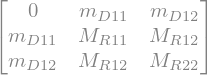

In [4]:
Mnu12 = seesaw12.full_mass_matrix_symbolic()
Mnu12

In [5]:
Mnu12.rank()

In [6]:
charpoly_relations = seesaw12.charpoly_relations()


In [7]:
mn = seesaw12.masses
mn

## First case

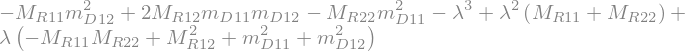

In [8]:
charpoly_relations['char_poly_M']

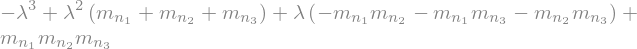

In [9]:
charpoly_relations['char_poly_diag']

In [10]:
r = symbols('r')
th = symbols('theta', real=True)

seesaw_parameters_polar = {
    seesaw12.m_D_sym[0, 0]: r * sin(th),
    seesaw12.m_D_sym[0, 1]: r * cos(th)
}
(seesaw12.m_D_sym[0, 0]**2 + seesaw12.m_D_sym[0, 1]**2).subs(
    seesaw_parameters_polar
).trigsimp()

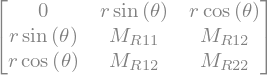

In [11]:
Mnu12_polar = Mnu12.subs(seesaw_parameters_polar)
Mnu12_polar

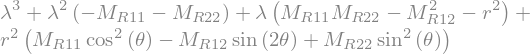

In [12]:
Mnu12_polar.charpoly().args[0]

In [188]:
charpoly_relations = seesaw12.charpoly_relations(substitutions=seesaw_parameters_polar)

In [ ]:
eqs_charpoly = [
    charpoly_relations['coefficients_full_matrix'][key].trigsimp()
    - charpoly_relations['coefficients_diagonal'][key]
    for key in charpoly_relations['coefficients_full_matrix']
]
eqs_charpoly

In [195]:
for eq in eqs_charpoly:
    display(eq)

In [15]:
MR1122_sol = solve(eqs_charpoly[2], seesaw12.M_R_sym[0, 0] + seesaw12.M_R_sym[1, 1], dict=True)[0]
MR1122_sol

In [16]:
MR1122_sum = seesaw12.M_R_sym[0, 0] + seesaw12.M_R_sym[1, 1]
(MR1122_sum**2).expand()

In [20]:
(MR1122_sol[MR1122_sum]**2).expand()

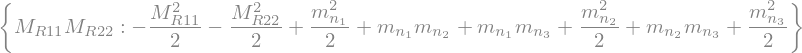

In [23]:
MR1122_times = seesaw12.M_R_sym[1, 1]*seesaw12.M_R_sym[0, 0]
MR1122_times_sol1 = solve(
    (MR1122_sum**2).expand()- (MR1122_sol[MR1122_sum]**2).expand(),
    MR1122_times, dict=True
)[0]
MR1122_times_sol1

In [27]:
MR1122_times_sol2 = solve(eqs_charpoly[1].expand(), MR1122_times, dict=True)[0]
MR1122_times_sol2

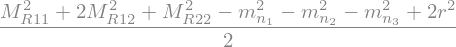

In [26]:
(MR1122_times_sol2[MR1122_times] - MR1122_times_sol1[MR1122_times]).factor()

In [30]:
(MR1122_sum**2).expand()

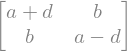

In [113]:
a,b,c,d = symbols('a b c d', real=True)
# Pauli matrices
sigma0 = Matrix(
    [
        [1,0],
        [0,1]
    ]
)
sigma1 = Matrix(
    [
        [0, 1],
        [1, 0]
    ]
)

sigma2 = Matrix(
    [
        [0, -I],
        [I, 0]
    ]
)

sigma3 = Matrix(
    [
        [1, 0],
        [0, -1]
    ]
)
M = a*sigma0 + b * sigma1  + d * sigma3 # + c * sigma2
M

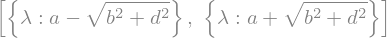

In [114]:
Mcharpoly = M.charpoly()
solve(Mcharpoly.args[0], Mcharpoly.args[1], dict=True)

In [115]:
MR_changes_sigma = {
    seesaw12.M_R_sym[0,0]:M[0,0],
    seesaw12.M_R_sym[0,1]:M[0,1],
    seesaw12.M_R_sym[1,1]:M[1,1]
}
MR_changes_sigma

In [116]:
eqs_charpoly_sigma = [eq.subs(MR_changes_sigma).simplify() for eq in eqs_charpoly]
eqs_charpoly_sigma

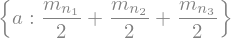

In [117]:
a_sol2 = solve(eqs_charpoly_sigma[2], a, dict=True)[0]
a_sol2

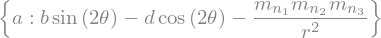

In [118]:
a_sol0 = solve(eqs_charpoly_sigma[0], a, dict=True)[0]
a_sol0

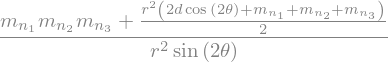

In [119]:
b_sol = solve(a_sol0[a] - a_sol2[a], b, dict=True)[0]
b_sol[b]#.expand().trigsimp().factor()

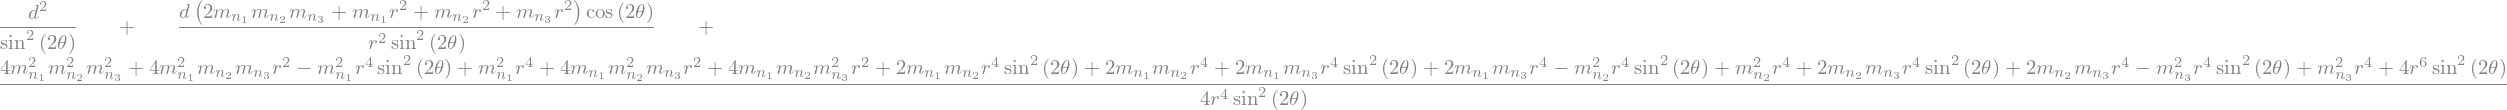

In [120]:
eqs_d = eqs_charpoly_sigma[1].subs(b_sol).subs(a_sol2).expand().collect(d, lambda x:x.factor().trigsimp())
eqs_d

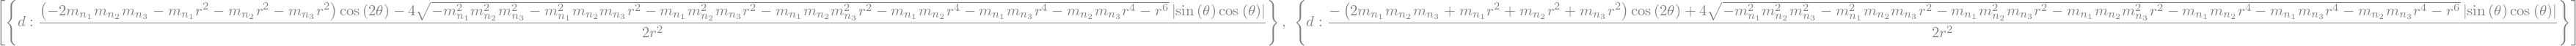

In [162]:
d_sol = solve(eqs_d, d, dict=True)
d_sol

In [163]:
qd = d_sol[0][d].args[2].args[1].args[2].args[0]
qd_factor = qd.factor()
qd_factor

In [164]:
pd = d_sol[0][d].args[2].args[0].args[0]
pd_collect = pd.collect(r, lambda x:x.simplify())
pd_collect

In [165]:
for dictionary in d_sol:
    for key, value in dictionary.items():
        dictionary[key] = value.subs(qd, qd_factor).subs(pd, pd_collect)


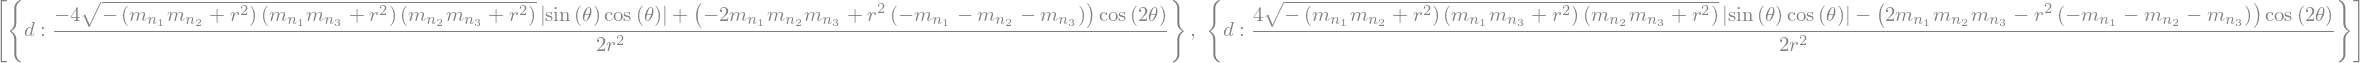

In [166]:
d_sol

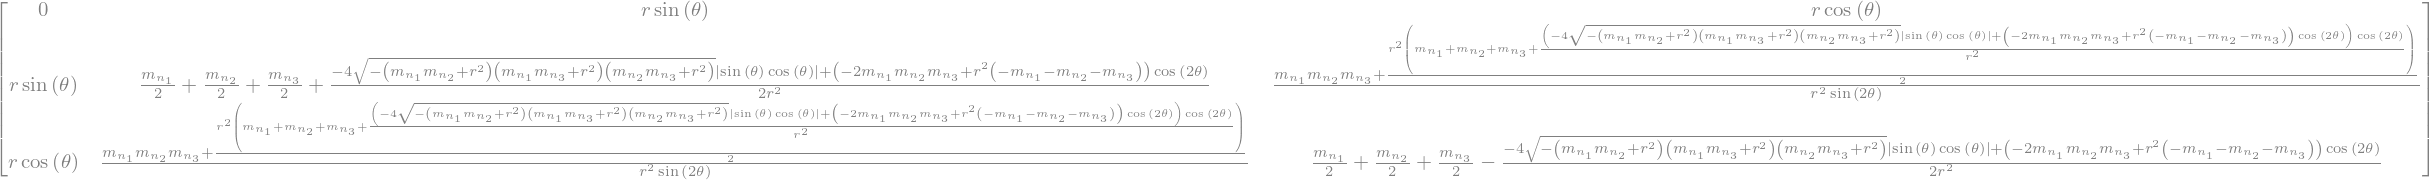

In [161]:
Mnu12_parametric = Mnu12_polar.subs(MR_changes_sigma).subs(b_sol).subs(a_sol2).subs(d_sol[0])
Mnu12_parametric

In [167]:
Mnu12_parametric.rank()

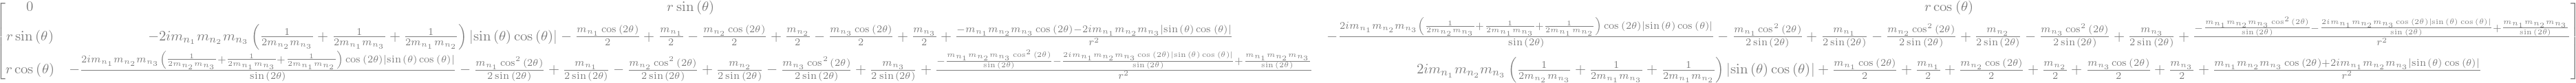

In [112]:
Mnu12_parametric_approx = Mnu12_parametric.applyfunc(lambda x: x.series(r, 0, 2).removeO())
Mnu12_parametric_approx

In [168]:
Mnu12_parametric_charpoly = Mnu12_parametric.charpoly()
Mnu12_parametric_charpoly

In [127]:
Mnu12_parametric_charpoly.args[0]

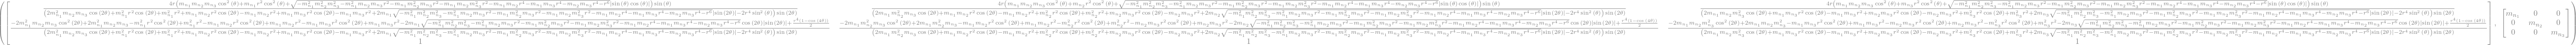

In [169]:
P,D = Mnu12_parametric.diagonalize()
P,D

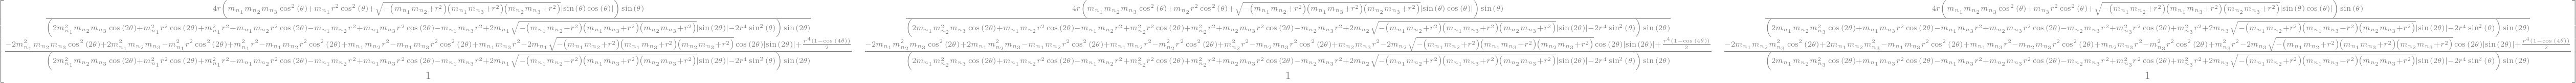

In [170]:
P.subs(qd, qd_factor)#.subs(pd, pd_collect)

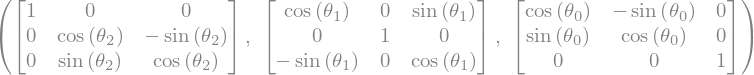

In [171]:
th0, th1, th2 = symbols(r'\theta_{0}, \theta_{1}, \theta_{2}', real=True)
Rth2 = symbolic_rotation_matrix(dim=3, axis=2, angle=th0)
Rth1 = symbolic_rotation_matrix(dim=3, axis=1, angle=th1)
Rth0 = symbolic_rotation_matrix(dim=3, axis=0, angle=th2)
Rth0, Rth1, Rth2

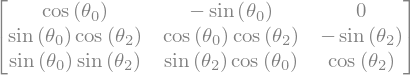

In [176]:
R = Rth0*Rth2
R

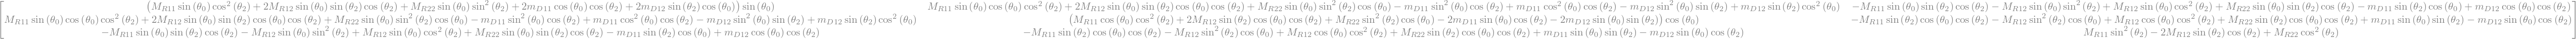

In [177]:
Mnu12_diag = (R.T*Mnu12*R).applyfunc(lambda x:x.factor())
Mnu12_diag

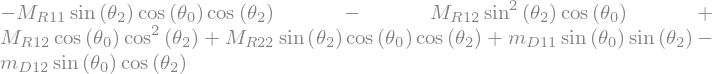

In [181]:
Mnu12_diag[2,1].factor()

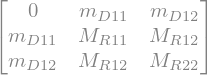

In [198]:
Mnu12

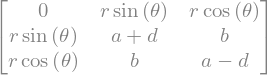

In [184]:
Mnu12.subs(seesaw_parameters_polar).subs(MR_changes_sigma)

## Second case

In [ ]:
charpoly_relations = seesaw12.charpoly_relations()
eqs_charpoly = [
    charpoly_relations['coefficients_full_matrix'][key].trigsimp()
    - charpoly_relations['coefficients_diagonal'][key]
    for key in charpoly_relations['coefficients_full_matrix']
]

for eq in eqs_charpoly:
    display(eq)

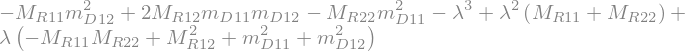

In [200]:
charpoly_relations['char_poly_M']


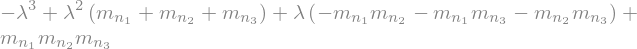

In [201]:
charpoly_relations['char_poly_diag']

$$m_{D\,11}=\rho>0$$

$$z\;=\;\frac{m_{D\,12}}{m_{D\,11}}\;\in\;\mathbb{C}.$$
$$S\;=\;m_{n_1}+m_{n_2}+m_{n_3},\qquad C\;=\;\frac{m_{n_1}m_{n_2}m_{n_3}}{\rho^{2}}.$$

$$M_{R\,11}+M_{R\,22}=S,$$
$$M_{R\,11}\,z^{2}-2\,M_{R\,12}\,z+\bigl(M_{R\,22}+C\bigr)=0.
$$

$$M_{R\,11}=t,\qquad M_{R\,22}=S-t.$$

$$M_{R\,12}\;=\;\frac{1}{2}\left(t\,z+\frac{S-t+C}{z}\right).$$

$$m_{D\,12}=z\,\rho.$$

Because $M_{R\,12}$ must be real, $z$ and $t$ cannot be arbitrary. Writing $z=r\,e^{i\theta}$ with $r>0$, the “reality” condition for $M_{R\,12}$ reduces to
$$\sin\theta\left(t\,r-\frac{S-t+C}{r}\right)=0.$$


This yields two families of solutions:
- $z\in\mathbb{R}$ (i.e., $\theta=0$ or $\pi$), any $r>0$.
- Or, if $\sin\theta\neq 0$,
$r^{2}\;=\;\frac{S-t+C}{t}$,
which requires $t>0$ and $S-t+C>0$.


Given $\rho>0$, a choice of $t$ within those constraints, and either a real $z$ or a complex $z$ with the above magnitude, you obtain a consistent real $M_{R\,12}$ and complex $m_{D\,12}$. This explicitly shows the continuous family of solutions.


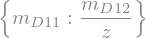

In [ ]:
z = symbols('z')
changes_parametric = {
    seesaw12.m_D_sym[0,0]:seesaw12.m_D_sym[0,1]/z,
    
}
changes_parametric

## Third case

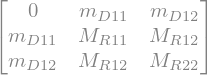

In [8]:
Mnu12 = seesaw12.full_mass_matrix_symbolic()
Mnu12

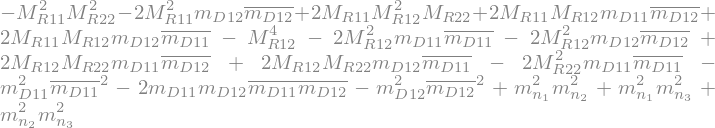

In [9]:
charpoly_relations = seesaw12.charpoly_relations_MDaggerM()
eqs_charpoly = [
    charpoly_relations['coefficients_full_matrix'][key].trigsimp()
    - charpoly_relations['coefficients_diagonal'][key]
    for key in charpoly_relations['coefficients_full_matrix']
]

for eq in eqs_charpoly:
    display(eq)

Assuming $M_{R12} = 0$ and $M_{R11}, M_{R22}$ positive and equal to heavy neutrino masses $M_1, M_2$, respectively. 

In [10]:
m, M1, M2 = symbols('m, M1, M2', positive=True)
simple_case = {
    seesaw12.M_R_sym[0,0]: M1,
    seesaw12.M_R_sym[1,1]: M2,
    seesaw12.M_R_sym[0,1]: 0
}
simple_case

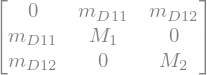

In [11]:
Mnu12_simple = Mnu12.subs(simple_case)
Mnu12_simple

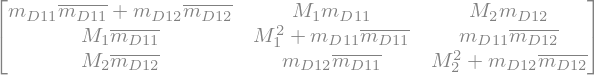

In [12]:
MMDagger12 = Mnu12_simple * Dagger(Mnu12_simple)
MMDagger12

In [13]:
masses_ss = seesaw12.masses
masses_changes = {
    masses_ss[0]:m,
    masses_ss[1]:M1,
    masses_ss[2]:M2
}

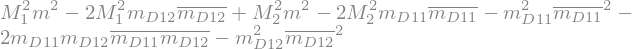

In [14]:
charpoly_relations = seesaw12.charpoly_relations_MDaggerM(substitutions=simple_case)
eqs_charpoly = [
    charpoly_relations['coefficients_full_matrix'][key]
    - charpoly_relations['coefficients_diagonal'][key].subs(masses_changes)
    for key in charpoly_relations['coefficients_full_matrix']
]

for eq in eqs_charpoly:
    display(eq)

In [15]:
m_square_sol = solve(eqs_charpoly[2], m**2, dict=True)[0]
m_square_sol

In [17]:
eqs_charpoly[0].subs(m_square_sol)

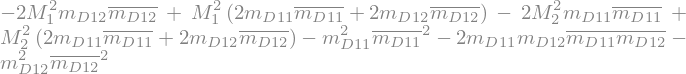

In [18]:
eqs_charpoly[1].subs(m_square_sol)

In [ ]:
mD12_square = solve(eqs_charpoly[2], seesaw12.m_D_sym[0,1]**2, dict=True)[0]
mD12_square

In [244]:
eqs_charpoly[0].subs(mD12_square)

In [245]:
solve(eqs_charpoly[1].subs(mD12_square), seesaw12.M_R_sym[0, 0]**2, dict=True)